In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    PolynomialFeatures,
)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


PROJECT_ROOT = Path("..")

external_dir = (
    PROJECT_ROOT
    / "data"
    / "external"
)

matches = list(
    external_dir.rglob("NACA0009.10")
)

if not matches:
    raise FileNotFoundError(
        "Could not find NACA0009.10 "
        "inside data/external."
    )

experimental_path = matches[0]

print(
    "Experimental file:",
    experimental_path
)

Experimental file: ..\data\external\NACA0009.10


In [2]:
with open(
    experimental_path,
    "r",
) as file:

    lines = file.readlines()


print("File header:")

for line in lines[:5]:
    print(line.strip())


experimental_rows = []

for line in lines[5:]:

    parts = line.split()

    if len(parts) >= 2:

        try:

            alpha = float(parts[0])
            cl = float(parts[1])

            experimental_rows.append(
                [alpha, cl]
            )

        except ValueError:
            pass


experimental = pd.DataFrame(
    experimental_rows,
    columns=[
        "alpha",
        "CL_exp",
    ],
)

print(
    "\nTotal experimental points:",
    len(experimental)
)

experimental.head()

File header:
N0009L100X.DAT;1
NACA 0009
NANKIVIL
100K  99944.
alpha   Cl

Total experimental points: 117


,alpha,CL_exp
0,-6.15,-0.56
1,-5.71,-0.53
2,-5.34,-0.50
3,-4.90,-0.47
4,-4.49,-0.43


In [3]:
turning_index = (
    experimental["alpha"].idxmax()
)

experimental_up = (
    experimental
    .loc[:turning_index]
    .copy()
)

print(
    "Ascending sweep points:",
    len(experimental_up)
)

print(
    "Maximum experimental angle:",
    experimental_up["alpha"].max()
)

Ascending sweep points: 59
Maximum experimental angle: 17.32


In [4]:
experimental_valid = (
    experimental_up[
        (
            experimental_up["alpha"]
            >= -6
        )
        &
        (
            experimental_up["alpha"]
            <= 12
        )
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    "Validation points:",
    len(experimental_valid)
)

print(
    "Validation angle range:",
    experimental_valid["alpha"].min(),
    "to",
    experimental_valid["alpha"].max(),
)

experimental_valid.head()

Validation points: 44
Validation angle range: -5.71 to 11.72


,alpha,CL_exp
0,-5.71,-0.53
1,-5.34,-0.50
2,-4.90,-0.47
3,-4.49,-0.43
4,-4.08,-0.40


In [5]:
dataset_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "airfoil_dataset_final.csv"
)

data = pd.read_csv(
    dataset_path
)


xfoil_0009 = (
    data[
        (data["airfoil"] == "NACA 0009")
        &
        (data["reynolds"] == 100000)
    ]
    .sort_values("alpha")
    .copy()
)


print(
    "XFOIL NACA 0009 points:",
    len(xfoil_0009)
)

xfoil_0009[
    [
        "alpha",
        "CL",
    ]
]

XFOIL NACA 0009 points: 19


,alpha,CL
0,-6.0,-0.6487
1,-5.0,-0.5577
2,-4.0,-0.4836
3,-3.0,-0.4028
4,-2.0,-0.2703
5,-1.0,-0.0344
6,0.0,-0.0000
7,1.0,0.0345
8,2.0,0.2703
9,3.0,0.4028


In [6]:
features = [
    "max_camber",
    "camber_position",
    "thickness",
    "reynolds",
    "alpha",
]


validation_train = data[
    data["airfoil"] != "NACA 0009"
].copy()


X_validation_train = (
    validation_train[features]
)

y_validation_train = (
    validation_train["CL"]
)


validation_model = Pipeline([
    (
        "scaler",
        StandardScaler(),
    ),
    (
        "poly",
        PolynomialFeatures(
            degree=3,
            include_bias=False,
        ),
    ),
    (
        "regression",
        LinearRegression(),
    ),
])


validation_model.fit(
    X_validation_train,
    y_validation_train,
)


print(
    "Validation model trained "
    "without NACA 0009."
)

print(
    "Training airfoils:",
    validation_train[
        "airfoil"
    ].nunique()
)

Validation model trained without NACA 0009.
Training airfoils: 20


In [7]:
experimental_inputs = pd.DataFrame({
    "max_camber": 0.0,
    "camber_position": 0.0,
    "thickness": 0.09,
    "reynolds": 99944,
    "alpha": experimental_valid["alpha"],
})


experimental_valid[
    "CL_surrogate"
] = validation_model.predict(
    experimental_inputs[features]
)


experimental_valid.head()

,alpha,CL_exp,CL_surrogate
0,-5.71,-0.53,-0.752919
1,-5.34,-0.50,-0.704244
2,-4.90,-0.47,-0.646117
3,-4.49,-0.43,-0.591786
4,-4.08,-0.40,-0.537364


In [8]:
experimental_valid[
    "CL_xfoil"
] = np.interp(
    experimental_valid["alpha"],
    xfoil_0009["alpha"],
    xfoil_0009["CL"],
)


experimental_valid[
    [
        "alpha",
        "CL_exp",
        "CL_xfoil",
        "CL_surrogate",
    ]
].head(15)

,alpha,CL_exp,CL_xfoil,CL_surrogate
0,-5.71,-0.53,-0.622310,-0.752919
1,-5.34,-0.50,-0.588640,-0.704244
2,-4.90,-0.47,-0.550290,-0.646117
3,-4.49,-0.43,-0.519909,-0.591786
4,-4.08,-0.40,-0.489528,-0.537364
5,-3.68,-0.38,-0.457744,-0.484246
6,-3.30,-0.35,-0.427040,-0.433822
7,-2.89,-0.31,-0.388225,-0.379522
8,-2.47,-0.26,-0.332575,-0.324082
9,-2.04,-0.21,-0.275600,-0.267590


In [9]:
xfoil_MAE = mean_absolute_error(
    experimental_valid["CL_exp"],
    experimental_valid["CL_xfoil"],
)

xfoil_RMSE = np.sqrt(
    mean_squared_error(
        experimental_valid["CL_exp"],
        experimental_valid["CL_xfoil"],
    )
)

xfoil_R2 = r2_score(
    experimental_valid["CL_exp"],
    experimental_valid["CL_xfoil"],
)


surrogate_MAE = mean_absolute_error(
    experimental_valid["CL_exp"],
    experimental_valid["CL_surrogate"],
)

surrogate_RMSE = np.sqrt(
    mean_squared_error(
        experimental_valid["CL_exp"],
        experimental_valid["CL_surrogate"],
    )
)

surrogate_R2 = r2_score(
    experimental_valid["CL_exp"],
    experimental_valid["CL_surrogate"],
)


print(
    "INDEPENDENT EXPERIMENTAL VALIDATION"
)

print(
    "-----------------------------------"
)


print("\nXFOIL vs wind tunnel:")

print(
    f"MAE  = {xfoil_MAE:.5f}"
)

print(
    f"RMSE = {xfoil_RMSE:.5f}"
)

print(
    f"R²   = {xfoil_R2:.5f}"
)


print(
    "\nSurrogate vs wind tunnel:"
)

print(
    f"MAE  = {surrogate_MAE:.5f}"
)

print(
    f"RMSE = {surrogate_RMSE:.5f}"
)

print(
    f"R²   = {surrogate_R2:.5f}"
)

INDEPENDENT EXPERIMENTAL VALIDATION
-----------------------------------

XFOIL vs wind tunnel:
MAE  = 0.06498
RMSE = 0.07141
R²   = 0.97289

Surrogate vs wind tunnel:
MAE  = 0.08558
RMSE = 0.10231
R²   = 0.94436


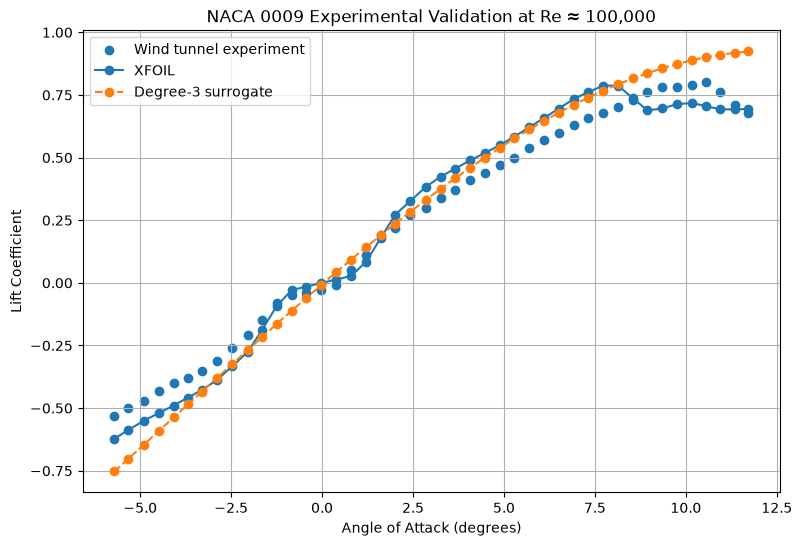

In [10]:
plt.figure(
    figsize=(9, 6)
)


plt.scatter(
    experimental_valid["alpha"],
    experimental_valid["CL_exp"],
    label="Wind tunnel experiment",
)


plt.plot(
    experimental_valid["alpha"],
    experimental_valid["CL_xfoil"],
    marker="o",
    label="XFOIL",
)


plt.plot(
    experimental_valid["alpha"],
    experimental_valid["CL_surrogate"],
    marker="o",
    linestyle="--",
    label="Degree-3 surrogate",
)


plt.xlabel(
    "Angle of Attack (degrees)"
)

plt.ylabel(
    "Lift Coefficient"
)

plt.title(
    "NACA 0009 Experimental Validation "
    "at Re ≈ 100,000"
)

plt.legend()

plt.grid()

plt.show()

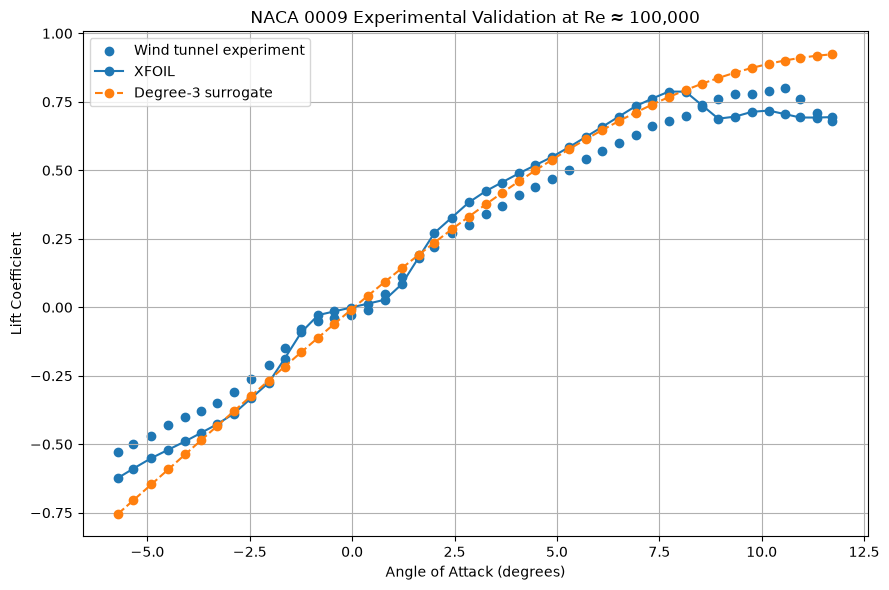

In [11]:
results_dir = (
    PROJECT_ROOT
    / "results"
)

results_dir.mkdir(
    parents=True,
    exist_ok=True,
)


plt.figure(
    figsize=(9, 6)
)

plt.scatter(
    experimental_valid["alpha"],
    experimental_valid["CL_exp"],
    label="Wind tunnel experiment",
)

plt.plot(
    experimental_valid["alpha"],
    experimental_valid["CL_xfoil"],
    marker="o",
    label="XFOIL",
)

plt.plot(
    experimental_valid["alpha"],
    experimental_valid["CL_surrogate"],
    marker="o",
    linestyle="--",
    label="Degree-3 surrogate",
)

plt.xlabel(
    "Angle of Attack (degrees)"
)

plt.ylabel(
    "Lift Coefficient"
)

plt.title(
    "NACA 0009 Experimental Validation "
    "at Re ≈ 100,000"
)

plt.legend()
plt.grid()
plt.tight_layout()

plt.savefig(
    results_dir
    / "naca0009_experimental_validation.png",
    dpi=300,
)

plt.show()